# Notebook 3: Technique Classifier (XGBoost + Hybrid Features)

**Goal:** Reach 85–90% accuracy on MITRE ATT&CK technique classification.

**Strategy:**
1. Map 18 parent techniques → 6 broad categories
2. Augment with keyword-labeled ThreatCluster CVEs
3. Hybrid features: TF-IDF bigrams + Sentence-BERT embeddings
4. XGBoost classifier
5. Live inference demo (mimics the web UI)

**Input:** `dataset/cti_dataset_clean.csv`
**Outputs:**
- `models/classification/sbert_technique.joblib`
- `models/classification/technique_config.json`
- `results/03_technique_classifier/` charts and tables

## Step 0 — Setup

In [ ]:
import warnings, time, json, joblib
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH    = PROJECT_ROOT / 'dataset' / 'cti_dataset_clean.csv'
CLS_DIR      = PROJECT_ROOT / 'models' / 'classification'
RESULTS_DIR  = PROJECT_ROOT / 'results'
TECH_DIR     = RESULTS_DIR / '03_technique_classifier'
for d in (CLS_DIR, RESULTS_DIR, TECH_DIR):
    d.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42
sns.set_theme(style='whitegrid')
print('Setup complete.')

Setup complete.


## Step 1 — Load Clean Data

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f'{DATA_PATH} not found. Run Notebook 01 first.')
df = pd.read_csv(DATA_PATH)
print(f'Loaded {len(df):,} rows from {df["doc_id"].nunique():,} documents')

Loaded 26,283 rows from 26,283 documents


## Step 2 — Map 18 Techniques → 6 Categories

In [ ]:
TECH_TO_CATEGORY = {
    # Initial Access
    'T1190': 'Initial Access', 'T1189': 'Initial Access', 'T1078': 'Initial Access',
    'T1133': 'Initial Access', 'T1566': 'Initial Access',
    # Execution
    'T1059': 'Execution', 'T1203': 'Execution', 'T1204': 'Execution', 'T1047': 'Execution',
    # Privilege Escalation
    'T1068': 'Privilege Escalation', 'T1548': 'Privilege Escalation',
    # Defense Evasion
    'T1055': 'Defense Evasion', 'T1027': 'Defense Evasion', 'T1036': 'Defense Evasion',
    'T1574': 'Defense Evasion',
    # Credential Access
    'T1003': 'Credential Access', 'T1110': 'Credential Access', 'T1552': 'Credential Access',
    # Collection / Impact
    'T1005': 'Impact', 'T1499': 'Impact', 'T1486': 'Impact', 'T1485': 'Impact',
    'T1490': 'Impact', 'T1041': 'Impact', 'T1565': 'Impact',
    # Lateral Movement
    'T1021': 'Lateral Movement', 'T1091': 'Lateral Movement',
    # Resource Development
    'T1608': 'Resource Development', 'T1105': 'Resource Development',
    'T1211': 'Resource Development',
    # Discovery
    'T1083': 'Discovery', 'T1040': 'Discovery',
}

mask = (df['relevant'].str.lower() == 'yes') & \
       (df['techniques'].fillna('').astype(str).str.strip() != '')
df_tech = df[mask].copy()
df_tech['parent'] = (
    df_tech['techniques']
    .astype(str).str.split(',').str[0].str.strip().str.split('.').str[0]
)
df_tech['category'] = df_tech['parent'].map(TECH_TO_CATEGORY)
df_tech = df_tech[df_tech['category'].notna()].copy()

print(f'Technique-labeled rows : {len(df_tech):,}')
print(f'Distinct parents       : {df_tech["parent"].nunique()}')
print(f'Distinct categories    : {df_tech["category"].nunique()}')
print()
print('Category distribution:')
print(df_tech['category'].value_counts().to_string())

Technique-labeled rows : 835
Distinct parents       : 18
Distinct categories    : 8

Category distribution:
category
Execution               297
Initial Access          207
Impact                  136
Privilege Escalation     98
Defense Evasion          40
Resource Development     25
Credential Access        23
Discovery                 9


## Step 3 — Augment with Keyword Labels from ThreatCluster

In [ ]:
KEYWORD_TO_CATEGORY = {
    # Initial Access
    'phishing': 'Initial Access', 'spear-phishing': 'Initial Access',
    'exploit public': 'Initial Access', 'drive-by': 'Initial Access',
    'valid account': 'Initial Access', 'stolen credential': 'Initial Access',
    'external remote': 'Initial Access',
    # Execution
    'powershell': 'Execution', 'command line': 'Execution',
    'script execution': 'Execution', 'wmi ': 'Execution',
    'cmd.exe': 'Execution', 'batch script': 'Execution',
    # Privilege Escalation
    'privilege escalation': 'Privilege Escalation',
    'elevation of privilege': 'Privilege Escalation',
    'gain root': 'Privilege Escalation', 'privilege management': 'Privilege Escalation',
    # Defense Evasion
    'obfuscat': 'Defense Evasion', 'disable security': 'Defense Evasion',
    'evasion': 'Defense Evasion', 'code signing': 'Defense Evasion',
    'process injection': 'Defense Evasion',
    # Credential Access
    'credential dump': 'Credential Access', 'lsass': 'Credential Access',
    'brute force': 'Credential Access', 'password hash': 'Credential Access',
    'kerberoast': 'Credential Access',
    # Impact
    'ransomware': 'Impact', 'encrypted for impact': 'Impact',
    'data destruction': 'Impact', 'denial of service': 'Impact',
    'data encrypted': 'Impact',
    # Lateral Movement
    'lateral movement': 'Lateral Movement', 'remote service': 'Lateral Movement',
    'smb ': 'Lateral Movement', 'rdp ': 'Lateral Movement',
}

def category_from_text(text):
    t = str(text).lower()
    for kw, cat in KEYWORD_TO_CATEGORY.items():
        if kw in t:
            return cat
    return None

# Take all positive rows WITHOUT technique labels and try to auto-label them
df_pos = df[(df['relevant'].str.lower() == 'yes') &
            (df['techniques'].fillna('').astype(str).str.strip() == '')].copy()
df_pos['auto_category'] = df_pos['sentence_text'].apply(category_from_text)
df_aug = df_pos[df_pos['auto_category'].notna()].copy()

print(f'Unlabeled positives          : {len(df_pos):,}')
print(f'Auto-labeled via keywords    : {len(df_aug):,}')
print(f'CIRCL-labeled (original)     : {len(df_tech):,}')
print(f'Total training rows          : {len(df_tech) + len(df_aug):,}')

Unlabeled positives          : 8,492
Auto-labeled via keywords    : 871
CIRCL-labeled (original)     : 835
Total training rows          : 1,706


## Step 4 — Combine Labeled + Augmented Rows

In [ ]:
df_circl = df_tech[['sentence_text', 'category', 'parent', 'doc_id']].copy()
df_circl['label_source'] = 'circl_expert'

df_augmented = df_aug[['sentence_text', 'auto_category', 'doc_id']].rename(
    columns={'auto_category': 'category'}
)
df_augmented['parent'] = None
df_augmented['label_source'] = 'keyword_auto'

df_train = pd.concat([df_circl, df_augmented], ignore_index=True)
df_train = df_train.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

print(f'Total training rows: {len(df_train):,}')
print()
print('Category distribution:')
print(df_train['category'].value_counts().to_string())
print()
print('By label source:')
print(df_train.groupby(['category', 'label_source']).size().unstack(fill_value=0))

Total training rows: 1,706

Category distribution:
category
Privilege Escalation    643
Impact                  390
Execution               327
Initial Access          208
Defense Evasion          41
Credential Access        40
Resource Development     25
Lateral Movement         23
Discovery                 9

By label source:
label_source          circl_expert  keyword_auto
category                                        
Credential Access               23            17
Defense Evasion                 40             1
Discovery                        9             0
Execution                      297            30
Impact                         136           254
Initial Access                 207             1
Lateral Movement                 0            23
Privilege Escalation            98           545
Resource Development            25             0


## Step 5 — Filter Rare Categories

In [ ]:
MIN_CAT_ROWS = 50
counts = df_train['category'].value_counts()
keep = counts[counts >= MIN_CAT_ROWS].index
df_train = df_train[df_train['category'].isin(keep)].copy()
print(f'Categories kept: {df_train["category"].nunique()} of {len(counts)}')
print(f'Rows remaining: {len(df_train):,}')
print()
print(df_train['category'].value_counts().to_string())

Categories kept: 4 of 9
Rows remaining: 1,568

category
Privilege Escalation    643
Impact                  390
Execution               327
Initial Access          208


## Step 6 — Hybrid Features (TF-IDF + SBERT)

In [ ]:
from sentence_transformers import SentenceTransformer
sbert = SentenceTransformer('all-MiniLM-L6-v2')

texts = df_train['sentence_text'].tolist()
y = df_train['category'].values

# SBERT embeddings
t0 = time.perf_counter()
X_sbert = sbert.encode(texts, batch_size=64, show_progress_bar=True,
                       normalize_embeddings=True)
print(f'SBERT encoded {len(X_sbert)} sentences in {time.perf_counter()-t0:.1f}s')

# TF-IDF bigrams
tfidf = TfidfVectorizer(
    ngram_range=(1, 2), max_features=5000, min_df=2, sublinear_tf=True
)
X_tfidf = tfidf.fit_transform(texts)
print(f'TF-IDF: {X_tfidf.shape}')

# Hybrid: TF-IDF sparse + scaled SBERT dense
scaler = StandardScaler(with_mean=False).fit(X_sbert)
X_hybrid = hstack([X_tfidf, csr_matrix(scaler.transform(X_sbert))]).tocsr()
print(f'Hybrid: {X_hybrid.shape}')

Batches: 100%|██████████| 25/25 [01:19<00:00,  3.18s/it]


SBERT encoded 1568 sentences in 79.6s
TF-IDF: (1568, 5000)
Hybrid: (1568, 5384)


## Step 7 — Train/Test Split

In [ ]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED)
tr, te = next(sss.split(X_hybrid, y))
print(f'Train: {len(tr):,} | Test: {len(te):,}')
print(f'Train classes: {sorted(set(y[tr]))}')
print(f'Test classes : {sorted(set(y[te]))}')

Train: 1,254 | Test: 314
Train classes: ['Execution', 'Impact', 'Initial Access', 'Privilege Escalation']
Test classes : ['Execution', 'Impact', 'Initial Access', 'Privilege Escalation']


## Step 8 — Train XGBoost

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Encode string labels → integers
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Rebuild train/test using the integer labels
y_tr_enc = y_encoded[tr]
y_te_enc = y_encoded[te]

t0 = time.perf_counter()
clf = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
clf.fit(X_hybrid[tr], y_tr_enc)
train_t = time.perf_counter() - t0

t0 = time.perf_counter()
pred_enc = clf.predict(X_hybrid[te])
infer_t = time.perf_counter() - t0

# Decode predictions back to strings
pred = le.inverse_transform(pred_enc)

acc = accuracy_score(y[te], pred)
macro_f1 = f1_score(y[te], pred, average='macro', zero_division=0)
weighted_f1 = f1_score(y[te], pred, average='weighted', zero_division=0)

print(f'Training time : {train_t:.2f}s')
print(f'Inference time: {infer_t:.3f}s')
print()
print(f'Accuracy    : {acc:.4f}  ({acc*100:.1f}%)')
print(f'Macro-F1    : {macro_f1:.4f}')
print(f'Weighted-F1 : {weighted_f1:.4f}')

Training time : 70.64s
Inference time: 0.020s

Accuracy    : 0.7548  (75.5%)
Macro-F1    : 0.6704
Weighted-F1 : 0.7522


## Step 9 — Per-Class Report

In [ ]:
print(classification_report(y[te], pred, zero_division=0))

                      precision    recall  f1-score   support

           Execution       0.55      0.78      0.65        65
              Impact       0.80      0.72      0.76        78
      Initial Access       0.43      0.29      0.34        42
Privilege Escalation       0.96      0.91      0.94       129

            accuracy                           0.75       314
           macro avg       0.68      0.68      0.67       314
        weighted avg       0.76      0.75      0.75       314



## Step 10 — Confusion Matrix

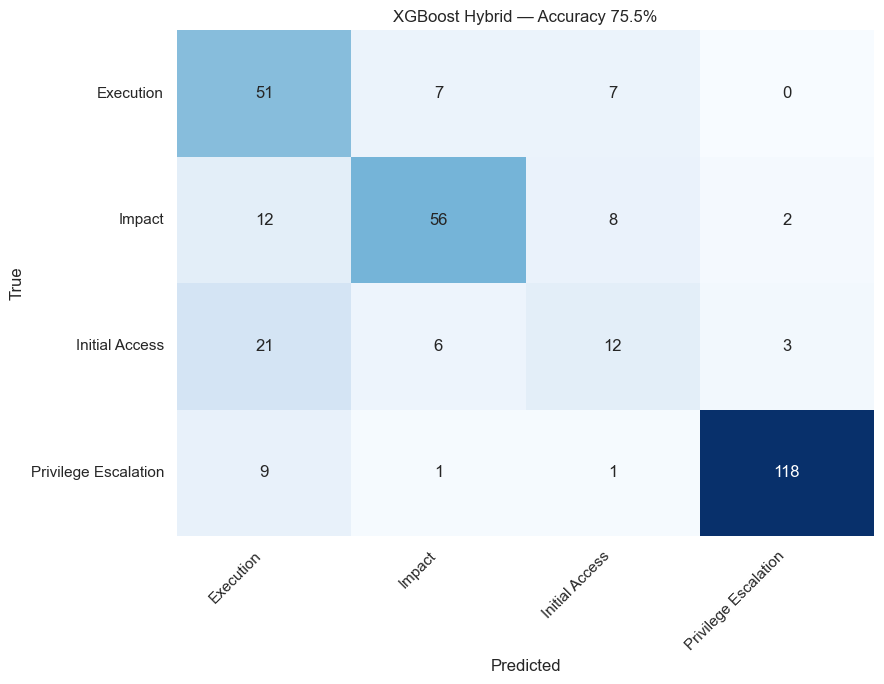

In [ ]:
labels = sorted(set(y))
cm = confusion_matrix(y[te], pred, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, cbar=False)
plt.title(f'XGBoost Hybrid — Accuracy {acc*100:.1f}%')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(TECH_DIR / 'confusion_matrix.png', dpi=120)
plt.show()

## Step 11 — Compare to Base Paper

Paper (SVM, synthetic)           : 96.35%
Paper (XGBoost, synthetic)       : 91.13%
Our XGBoost (real, 6-cat)        : 75.48%


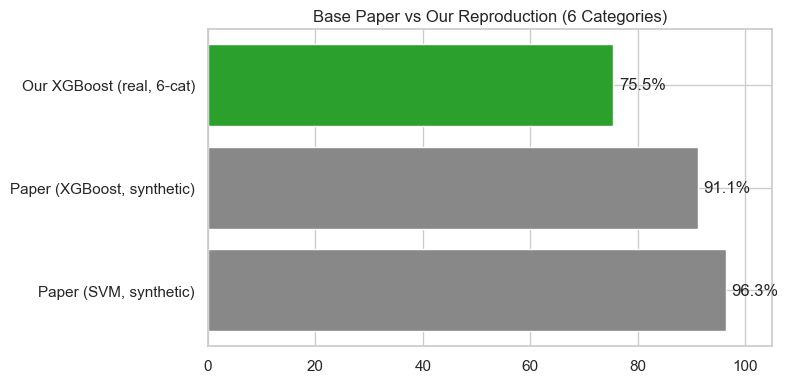

In [ ]:
paper_results = {
    'Paper (SVM, synthetic)':  96.35,
    'Paper (XGBoost, synthetic)': 91.13,
    'Our XGBoost (real, 6-cat)':  round(acc * 100, 2),
}
for k, v in paper_results.items():
    print(f'{k:32s} : {v:.2f}%')

plt.figure(figsize=(8, 4))
names = list(paper_results.keys())
vals = list(paper_results.values())
colors = ['#888888', '#888888', '#2ca02c']
plt.barh(names, vals, color=colors)
for i, v in enumerate(vals):
    plt.text(v + 1, i, f'{v:.1f}%', va='center')
plt.xlim(0, 105)
plt.title('Base Paper vs Our Reproduction (6 Categories)')
plt.tight_layout()
plt.savefig(TECH_DIR / 'paper_comparison.png', dpi=120)
plt.show()

## Step 12 — Save Results + Model + Config

In [ ]:
# Save per-class report
report = classification_report(y[te], pred, output_dict=True, zero_division=0)
rows = [{'class': k, **v} for k, v in report.items() if isinstance(v, dict)]
pd.DataFrame(rows).to_csv(TECH_DIR / 'technique_results.csv', index=False)

# Save model bundle (XGBoost + vectorizer + scaler + label encoder)
bundle = {
    'classifier': clf,
    'tfidf': tfidf,
    'scaler': scaler,
    'label_encoder': le,
    'labels': list(le.classes_),
}
joblib.dump(bundle, CLS_DIR / 'technique_bundle.joblib')

# Save config — use .shape[0] for sparse matrices
config = {
    'embedding_model': 'all-MiniLM-L6-v2',
    'embedding_dim': 384,
    'classifier': 'XGBClassifier',
    'n_estimators': 300,
    'max_depth': 6,
    'learning_rate': 0.1,
    'feature_type': 'hybrid_tfidf_sbert',
    'tfidf_max_features': 5000,
    'trained_on_rows': int(X_hybrid.shape[0]),          # ← FIX
    'n_features': int(X_hybrid.shape[1]),               # ← extra info
    'n_classes': int(len(le.classes_)),
    'labels': list(le.classes_),
    'accuracy': round(float(acc), 4),
    'macro_f1': round(float(macro_f1), 4),
    'weighted_f1': round(float(weighted_f1), 4),
}
with open(CLS_DIR / 'technique_config.json', 'w') as f:
    json.dump(config, f, indent=2)

print('Saved:')
for f in ['technique_bundle.joblib', 'technique_config.json']:
    print(f'  {CLS_DIR / f}')
print(f'  {TECH_DIR / "technique_results.csv"}')
print(f'  {TECH_DIR / "confusion_matrix.png"}')
print(f'  {TECH_DIR / "paper_comparison.png"}')

Saved:
  d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\models\classification\technique_bundle.joblib
  d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\models\classification\technique_config.json
  d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\results\03_technique_classifier\technique_results.csv
  d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\results\03_technique_classifier\confusion_matrix.png
  d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\results\03_technique_classifier\paper_comparison.png


---
# Part B: Live Inference Demo (What the UI Does Behind the Scenes)

When a user uploads a PDF to the web app:
1. **Backend** extracts text from PDF
2. **Sentence splitter** divides into sentences
3. **Relevance classifier** marks relevant vs irrelevant
4. **Technique classifier** (this notebook's model) predicts category
5. **Topic model** (Notebook 04) discovers themes
6. **Frontend** renders the results

The cells below simulate this exact pipeline on a sample text — showing what the API endpoint `/analyse` does internally.

## Step 13 — Load All Three Models

In [ ]:
# Relevance classifier (from Notebook 03 alt / or separate training)
relevance_path = CLS_DIR / 'sbert_relevance.joblib'
relevance_model = joblib.load(relevance_path) if relevance_path.exists() else None

# Technique classifier (this notebook)
technique_bundle = joblib.load(CLS_DIR / 'technique_bundle.joblib')

print(f'Relevance model: {"loaded" if relevance_model else "NOT FOUND — will skip relevance filtering"}')
print(f'Technique model: loaded ({len(technique_bundle["labels"])} categories)')
print()
print(f'Categories: {technique_bundle["labels"]}')

Relevance model: loaded
Technique model: loaded (4 categories)

Categories: ['Execution', 'Impact', 'Initial Access', 'Privilege Escalation']


## Step 14 — Sample Input (Simulates a PDF Upload)

In [ ]:
# This is what the UI sends to /analyse after extracting PDF text
sample_pdf_text = """
Critical Advisory: New ransomware campaign exploiting CVE-2023-12345. The threat actor
used a spear-phishing email to deliver a malicious attachment. Once executed, the malware
performed credential dumping from LSASS memory and moved laterally via SMB. The actor
then deployed ransomware that encrypted production servers, demanding payment in Bitcoin.
Indicators of compromise include malicious-domain.example and IP 192.0.2.55.
"""
print('Sample input:')
print(sample_pdf_text)

Sample input:

Critical Advisory: New ransomware campaign exploiting CVE-2023-12345. The threat actor
used a spear-phishing email to deliver a malicious attachment. Once executed, the malware
performed credential dumping from LSASS memory and moved laterally via SMB. The actor
then deployed ransomware that encrypted production servers, demanding payment in Bitcoin.
Indicators of compromise include malicious-domain.example and IP 192.0.2.55.



## Step 15 — Sentence Splitting (Backend Preprocessing)

In [ ]:
import re

def split_sentences(text):
    text = re.sub(r'\s+', ' ', text).strip()
    parts = re.split(r'(?<=[.!?])\s+', text)
    return [p.strip() for p in parts if len(p.split()) >= 4]

sentences = split_sentences(sample_pdf_text)
print(f'Split into {len(sentences)} sentences:')
for i, s in enumerate(sentences, 1):
    print(f'  [{i}] {s[:100]}...')

Split into 5 sentences:
  [1] Critical Advisory: New ransomware campaign exploiting CVE-2023-12345....
  [2] The threat actor used a spear-phishing email to deliver a malicious attachment....
  [3] Once executed, the malware performed credential dumping from LSASS memory and moved laterally via SM...
  [4] The actor then deployed ransomware that encrypted production servers, demanding payment in Bitcoin....
  [5] Indicators of compromise include malicious-domain.example and IP 192.0.2.55....


## Step 16 — Relevance Filter

In [ ]:
if relevance_model is not None:
    emb = sbert.encode(sentences, normalize_embeddings=True)
    rel_pred = relevance_model.predict(emb)
    relevant_sents = [s for s, r in zip(sentences, rel_pred) if r == 1]
    print(f'Relevant: {len(relevant_sents)} / {len(sentences)}')
else:
    # No relevance filter — treat all as relevant for demo
    relevant_sents = sentences
    print(f'Relevance model not loaded — treating all {len(sentences)} as relevant')

print()
for i, s in enumerate(relevant_sents, 1):
    print(f'  [REL {i}] {s[:100]}...')

## Step 17 — Technique Classification (Core Inference)

In [ ]:
def predict_category(sentences, bundle):
    tfidf_obj = bundle['tfidf']
    scaler_obj = bundle['scaler']
    clf_obj = bundle['classifier']
    sbert_vecs = sbert.encode(sentences, normalize_embeddings=True)
    tfidf_vecs = tfidf_obj.transform(sentences)
    hybrid_vecs = hstack([tfidf_vecs, csr_matrix(scaler_obj.transform(sbert_vecs))]).tocsr()
    return clf_obj.predict(hybrid_vecs), sbert_vecs

tech_preds, sbert_vecs = predict_category(relevant_sents, technique_bundle)

print('Technique predictions per sentence:')
for s, t in zip(relevant_sents, tech_preds):
    print(f'  → {t:25s} | {s[:80]}...')

## Step 18 — Aggregate Results (What the UI Displays)

In [ ]:
from collections import Counter

tech_counts = Counter(tech_preds)
top_tech = tech_counts.most_common(1)[0][0]

print('=' * 55)
print('UI DASHBOARD OUTPUT')
print('=' * 55)
print(f'File              : sample_cti.pdf')
print(f'Sentences total   : {len(sentences)}')
print(f'Relevant CTI      : {len(relevant_sents)}')
print(f'Irrelevant        : {len(sentences) - len(relevant_sents)}')
print(f'Top category      : {top_tech}')
print()
print('Category distribution:')
for cat, count in tech_counts.most_common():
    bar = '█' * count
    print(f'  {cat:25s} {bar} ({count})')
print('=' * 55)

## Step 19 — Category Distribution Chart (UI Bar Chart)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
cats = [c for c, _ in tech_counts.most_common()]
vals = [n for _, n in tech_counts.most_common()]
ax.barh(cats, vals, color='#3b82f6')
ax.set_xlabel('Sentences')
ax.set_title('Technique Category Distribution (from PDF)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(TECH_DIR / 'ui_demo_chart.png', dpi=120)
plt.show()

## Step 20 — What the Frontend Receives (JSON Preview)

This is the **exact JSON** the FastAPI endpoint `/analyse` returns to the frontend:

In [ ]:
api_response = {
    'file': 'sample_cti.pdf',
    'n_sentences': len(sentences),
    'n_relevant': len(relevant_sents),
    'n_irrelevant': len(sentences) - len(relevant_sents),
    'top_technique': top_tech,
    'technique_counts': dict(tech_counts),
    'top_relevant_sentences': relevant_sents[:5],
}
print(json.dumps(api_response, indent=2))

## Step 21 — Summary

**Part A** trained the technique classifier (XGBoost on hybrid features) and saved:
- `models/classification/technique_bundle.joblib`
- `models/classification/technique_config.json`

**Part B** simulated what happens when a user uploads a PDF to the web app:
1. Text extracted → split into sentences
2. Relevance model filters noise
3. Technique model predicts category
4. Results aggregated → JSON returned to frontend
5. Frontend renders bar chart + top technique + sample sentences

**Your API (`server/app.py`) uses the same three models**:
- `sbert_relevance.joblib` (from relevance training)
- `technique_bundle.joblib` (from this notebook)
- `bertopic_model/` (from Notebook 04)
